# Human Activity Recognition & Behavioral Pattern Analysis

## Projektübersicht

Dieses Notebook analysiert menschliche Bewegungsmuster basierend auf Sensordaten aus zwei Datensätzen:

- **KU-HAR**: Hochdimensionale, vorverarbeitete Feature-Zeitfenster von jüngeren Probanden (18 Aktivitätsklassen, 20.750 Samples)
- **HAR70+**: Einfachere Rohsensordaten von älteren Probanden (70+)

**Zentrale Fragestellung:** Wie lassen sich menschliche Bewegungsmuster aus Sensordaten erkennen und unterscheiden?

**Methoden:**
- Explorative Datenanalyse (EDA)
- Feature Engineering (Mittelwert, Varianz, Standardabweichung, Energie)
- Unsupervised Learning (K-Means Clustering + PCA)
- Supervised Learning (Random Forest Klassifikation)
- Datensatzvergleich KU-HAR vs. HAR70+

**Ergebnis:** Der Random Forest Klassifikator erreicht 92 % Accuracy auf KU-HAR und 96 % auf HAR70+. Das Clustering identifiziert Laufen als energetischen Ausreißer, der sich klar von allen anderen Aktivitäten trennt.

## Exploratory Data Analysis (EDA)

Analyse von menschlichen Bewegungsmustern basierend auf KU-HAR und HAR70+ Sensordaten.

In [1]:
from pathlib import Path

import pandas as pd # Ermöglicht das Laden und Manipulieren von Tabellen (DataFrames)
import numpy as np  # Für schnelle mathematische Operationen auf Arrays
import matplotlib.pyplot as plt # Bildet die Basis für alle Grafiken in diesem Notebook
import seaborn as sns # Für moderne statistische Grafiken (z.B. Heatmaps)

# Setzt die Anzeige auf max. 200 Spalten, damit Pandas hochdimensionale Daten nicht mit '...' abkürzt
pd.set_option('display.max_columns', 200)

# Datenordner relativ zum Notebook (Download-Anleitung: ../data/README.md)
DATA_DIR = Path("../data")


## 1. Daten laden

In diesem Schritt wird der KU-HAR-Hauptdatensatz (Kuhn-University Human Activity Recognition) in das Projekt geladen. Dieser enthält vorverarbeitete Zeitfenster im Zeitbereich (*Time Domain Subsamples*).

In [2]:
df_kuhar = pd.read_csv(
    DATA_DIR / "kuhar" / "KU-HAR_time_domain_subsamples_20750x300.csv"
)

df_kuhar.shape # Überprüft die Dimensionen der Daten direkt nach dem Laden. Dies ist eine wichtige Qualitätskontrolle. Die Ausgabe `(20749, 1803)` bedeutet: Der Datensatz enthält **20.749 Beobachtungen (Samples)** und **1.803 Merkmale (Features)**.

(20749, 1803)

Bereinigung der Spaltenbezeichnungen (Spalten-Renaming). Für eine saubere Datenanalyse und eine bessere Interpretierbarkeit müssen unklare oder kryptische Spaltennamen korrigiert werden.

In [3]:
# Benennt die Spalte mit dem Namen '0' in 'activity' um.
# Das Argument 'columns' nimmt ein Dictionary entgegen: {'alter_name': 'neuer_name'}.
# Das Ergebnis wird direkt in der Variable 'df_kuhar' überschrieben.

df_kuhar = df_kuhar.rename(columns={'0': 'activity'})

## 2. HAR70+ Daten laden

Dynamisches Laden und Zusammenführen der HAR70+ Daten. Im Gegensatz zum KU-HAR-Datensatz liegen die Daten für HAR70+ (ältere Probanden) in mehreren separaten CSV-Dateien vor – vermutlich aufgeteilt nach einzelnen Probanden. Dieser Code-Block automatisiert das Laden und Zusammenführen dieser Dateien.

In [4]:
# Durchsucht den Zielordner mithilfe des Platzhalters (`*.csv`) und findet automatisch alle CSV-Dateien. Das verhindert, dass jede Datei einzeln und manuell eingelesen werden muss (hartcodiert).
har70_files = sorted((DATA_DIR / "har70").glob("*.csv"))

if not har70_files:
    raise FileNotFoundError("Keine HAR70+ CSV-Dateien gefunden. Bitte Pfad prüfen.")

# List Comprehension durchläuft die Pfadliste in einer Schleife, liest jede Datei ein und speichert die DataFrames temporär in einer Liste ab.
dfs = [pd.read_csv(f) for f in har70_files]

# Verknüpft die einzelnen Tabellen zeilenweise (untereinander) zu einem Gesamt-DataFrame. Durch `ignore_index=True` wird der Index komplett neu von 0 bis zur Gesamtzahl durchgezählt, anstatt die Indizes der Originaldateien (die jeweils wieder bei 0 starten) zu duplizieren.
df_har70 = pd.concat(dfs, ignore_index=True) 

print(df_har70.shape)
df_har70.head()

(1832560, 8)


,timestamp,back_x,back_y,back_z,thigh_x,thigh_y,thigh_z,label
0,2021-03-24 14:42:03.839,-0.999023,-0.063477,0.140625,-0.980469,-0.112061,-0.048096,6
1,2021-03-24 14:42:03.859,-0.980225,-0.079346,0.140625,-0.961182,-0.121582,-0.051758,6
2,2021-03-24 14:42:03.880,-0.950195,-0.076416,0.140625,-0.949463,-0.080566,-0.067139,6
3,2021-03-24 14:42:03.900,-0.954834,-0.059082,0.140381,-0.957520,-0.046143,-0.050781,6
4,2021-03-24 14:42:03.920,-0.972412,-0.042969,0.142822,-0.977051,-0.023682,-0.026611,6


*   **`timestamp`**: Der exakte Zeitstempel der Messung. Die Daten wurden mit einer Frequenz 
    von 50 Hz aufgezeichnet (alle 20 Millisekunden ein neuer Messwert, erkennbar an `.839 -> .859 -> .880`).
*   **`back_x`, `back_y`, `back_z`**: Die Beschleunigungswerte (in g-Kraft) eines Sensors, der am 
    **unteren Rücken** (Back) des Probanden befestigt war, gemessen auf der X-, Y- und Z-Achse.
*   **`thigh_x`, `thigh_y`, `thigh_z`**: Die Beschleunigungswerte eines zweiten Sensors, der am 
    **Oberschenkel** (Thigh) angebracht war.
*   **`label`**: Die Zielvariable (Target). Die Zahl (hier die `6`) steht codiert für eine 
    bestimmte Aktivität (z. B. Sitzen oder Gehen), die wir später entschlüsseln und vorhersagen.

## 3. Datenstruktur verstehen

In diesem Abschnitt wird die Struktur der beiden Datensätze KU-HAR und HAR70+ untersucht. Ziel ist es, ein grundlegendes Verständnis der enthaltenen Variablen, Datenformate und Unterschiede zwischen den Datensätzen zu gewinnen.

### 3.1 Überblick über den KU-HAR Datensatz

In [5]:
df_kuhar.shape

(20749, 1803)

In [6]:
df_kuhar.head()

,0.0042305,-0.00028038,-0.013906,-0.0025436,0.027433,0.0583,0.05167,0.071857,0.080653,0.047917,0.02598,-0.004505,-0.0069016,0.0014359,0.0054108,0.013539,-0.0044653,0.0021413,0.00072683,0.016487,0.042913,0.044556,0.050468,0.051584,0.037475,0.032226,0.022386,0.0029199,-0.0078181,-0.011377,0.0066152,0.020155,0.032267,0.019457,0.0013083,-0.0032845,0.0044572,0.0094892,0.019808,0.010865,0.001005,0.004844,0.02584,0.048978,0.04342,0.042094,0.05251,0.017633,0.005716,0.00045321,-0.016052,-0.02107,0.0031951,0.006464,0.036121,0.047024,0.045971,0.020386,-0.0077681,-0.02736,-0.046509,-0.0099182,0.024809,0.04629,0.069207,0.055801,0.037053,-0.0012023,-0.013095,-0.026778,-0.046789,-0.029479,0.0037478,0.031252,0.04386,0.039791,0.063073,0.052131,0.052188,0.029347,-0.03698,-0.062974,-0.076304,-0.046323,-0.010209,-0.0057399,0.027237,0.052023,0.060295,0.054536,0.042911,0.014123,-0.017551,-0.010735,-0.014862,0.010101,0.039481,0.051133,0.08198,0.10427,...,-0.019537,-0.016986,-0.01305,-0.015554,-0.01233,-0.011619,-0.014508,-0.014963,-0.014059,-0.011111,-0.0088209.1,2.4975e-05,0.0035556,0.0047787,0.0065822,0.0070712,0.0056551,0.00012165,-0.0019703,-0.007048,-0.012466,-0.013288,-0.014328,-0.012572.1,-0.0081469,-0.0019607,0.0018916,0.0023903,0.0025417,-0.0016329,-0.0041714,-0.0070125,-0.010955,-0.014844,-0.01547,-0.014851,-0.014962,-0.01312,-0.0049613,-0.0012347,0.0003759,0.00044888,0.0015211,-0.0012209,-0.0049602,-0.0073042,-0.011468.1,-0.010022,-0.011326,-0.0092531,-0.0057666.3,-0.0062518,-0.0038926,-0.0064852,-0.010486,-0.014204,-0.014932,-0.01554,-0.016508,-0.012828,-0.01373,-0.01156,-0.0092243,-0.0098244,-0.010757,-0.012215,-0.0141,-0.015831,-0.017634,-0.020701,-0.021868,-0.020199,-0.019682,-0.016522,-0.012467,-0.011263,-0.012051,-0.012517,-0.013545,-0.015738,-0.016339.1,-0.017913,-0.015774,-0.014413,-0.011026,-0.0089429,-0.0098173,-0.0077866,-0.010366,-0.015142,-0.016692,-0.018566,-0.017361,-0.017919,-0.01668,-0.01665,-0.013097,activity,300,1
0,0.012482,0.032496,0.067856,0.071552,0.078103,0.040353,-0.001059,-0.018580,-0.026813,-0.011280,-0.004318,-0.006419,0.001323,0.011715,0.037722,0.043391,0.016934,-0.001675,-0.039222,-0.045895,-0.025795,-0.019383,0.005151,0.035842,0.049522,0.062814,0.065271,0.066347,0.049028,0.007227,-0.021317,-0.043519,-0.047830,-0.031877,0.058457,0.057251,0.040432,0.024931,0.016128,0.010744,-0.001581,-0.023355,-0.000559,-0.002667,0.011023,0.016799,0.002119,-0.005825,0.001007,0.023712,0.032978,0.057307,0.076718,0.078569,0.071640,0.029701,-0.006015,-0.030955,-0.034410,-0.047164,-0.036313,-0.016578,0.015336,0.065240,0.088213,0.081708,0.068788,0.024455,-0.004315,-0.022643,-0.019967,-0.023725,-0.001645,0.013225,0.043135,0.052318,0.061102,0.054015,0.043864,0.025463,0.009057,-0.019412,-0.045440,-0.047466,-0.014869,0.026164,0.043539,0.051884,0.073053,0.075172,0.071933,0.031286,-0.002910,-0.035842,-0.043488,-0.051534,-0.035630,-0.006728,0.013260,0.045750,...,0.000800,-0.001990,-0.004404,-0.007375,-0.011280,-0.011426,-0.009479,-0.008445,-0.001868,-0.000664,0.000328,-0.000245,-0.000685,-0.003850,-0.006052,-0.008365,-0.009107,-0.011264,-0.005565,-0.005168,-0.002812,0.003256,0.004478,0.002260,0.002852,0.001966,-0.000471,-0.001537,-0.003060,-0.006470,-0.004778,-0.005593,-0.006156,-0.002443,-0.001391,0.001063,0.003411,0.002962,0.004206,-0.000630,-0.002712,-0.007228,-0.008719,-0.006988,-0.006588,-0.001789,-0.002524,-0.000972,-0.003534,-0.004872,-0.007599,-0.011514,-0.013552,-0.011839,-0.011249,-0.007125,-0.006967,-0.005767,-0.004226,-0.003311,-0.004149,-0.006542,-0.010643,-0.011264,-0.010903,-0.011481,-0.008594,-0.008619,-0.006931,-0.006759,-0.005156,-0.005744,-0.005208,-0.005714,-0.006249,-0.009100,-0.009597,-0.011211,-0.010227,-0.011854,-0.009535,-0.008075,-0.007309,-0.005309,-0.004545,-0.004736,-0.005894,-0.005661,-0.006075,-0.007766,-0.008210,-0.010408,-0.011459,-0.011747,-0.010394,-0.008070,-0.004354,0,300,2
1,0.012127,0.028458,0.062075,0.052611,0.022942,-0.010017,-0.023151,-0.028515,0.005036,0.008450,0.009136,0.006218,0.024431,0.058240,

In [7]:
df_kuhar.info()

<class 'pandas.DataFrame'>
RangeIndex: 20749 entries, 0 to 20748
Columns: 1803 entries, 0.0042305 to 1
dtypes: float64(1800), int64(3)
memory usage: 285.4 MB


Der KU-HAR Datensatz enthält eine große Anzahl an Features, die aus Sensordaten (Beschleunigung und Rotation) abgeleitet wurden. Jede Zeile repräsentiert ein Zeitfenster einer bestimmten Aktivität.

### 3.2 Überblick über den HAR70+ Datensatz

In [8]:
df_har70.shape

(1832560, 8)

In [9]:
df_har70.head()

,timestamp,back_x,back_y,back_z,thigh_x,thigh_y,thigh_z,label
0,2021-03-24 14:42:03.839,-0.999023,-0.063477,0.140625,-0.980469,-0.112061,-0.048096,6
1,2021-03-24 14:42:03.859,-0.980225,-0.079346,0.140625,-0.961182,-0.121582,-0.051758,6
2,2021-03-24 14:42:03.880,-0.950195,-0.076416,0.140625,-0.949463,-0.080566,-0.067139,6
3,2021-03-24 14:42:03.900,-0.954834,-0.059082,0.140381,-0.957520,-0.046143,-0.050781,6
4,2021-03-24 14:42:03.920,-0.972412,-0.042969,0.142822,-0.977051,-0.023682,-0.026611,6


In [10]:
df_har70.info()

<class 'pandas.DataFrame'>
RangeIndex: 1832560 entries, 0 to 1832559
Data columns (total 8 columns):
 #   Column     Dtype  
---  ------     -----  
 0   timestamp  str    
 1   back_x     float64
 2   back_y     float64
 3   back_z     float64
 4   thigh_x    float64
 5   thigh_y    float64
 6   thigh_z    float64
 7   label      int64  
dtypes: float64(6), int64(1), str(1)
memory usage: 111.9 MB


Der HAR70+ Datensatz enthält weniger Features und basiert stärker auf kontinuierlichen Sensordaten. Die Struktur ist einfacher und näher an realen Messungen im Alltag.

## 3.3 Vergleich der Datenstrukturen und Harmonisierung

In diesem Abschnitt werden die strukturellen Eigenschaften der beiden Datensätze direkt gegenübergestellt, um die methodische Herausforderung des Projekts zu verdeutlichen.

*   **KU-HAR (Jüngere Probanden):** Besitzt `20.749` Zeilen und `1.803` Spalten. Es handelt sich um ein hochdimensionales, stark vorverarbeitetes Format, bei dem Zeitfenster als Features nebeneinandergelegt wurden.
*   **HAR70+ (Ältere Probanden):** Besitzt `1.832.560` Zeilen, aber nur `8` Spalten. Dies repräsentiert eine klassische, lange Zeitreihe mit kontinuierlichen Rohdaten.

**Fazit für die Analyse:** Aufgrund dieser fundamentalen strukturellen Unterschiede können die Datensätze nicht direkt miteinander vermischt werden. Sie müssen entweder separat modelliert oder durch gezielte Merkmalsextraktion (Feature Engineering) auf eine gemeinsame mathematische Basis gebracht werden.

In [11]:
print("KU-HAR Shape:", df_kuhar.shape)
print("HAR70 Shape:", df_har70.shape)

KU-HAR Shape: (20749, 1803)
HAR70 Shape: (1832560, 8)


In [12]:
print("KU-HAR Features:", len(df_kuhar.columns))
print("HAR70 Features:", len(df_har70.columns))

KU-HAR Features: 1803
HAR70 Features: 8


## 3.4 Umwandlung der Aktivitätslabels (Mapping)

Die Zielvariablen (Labels) liegen in den Quelldaten als numerische IDs (0 bis 17) vor. Für eine intuitive Interpretation der späteren Klassifikations- und Clustering-Ergebnisse wird ein sprechendes Text-Mapping durchgeführt.

*   **`activity_map`**: Ein Python-Dictionary, das jeder Ganzzahl-ID den exakten biologischen Namen der Aktivität zuordnet (z. B. `0: "Stand"`, `11: "Walk"`, `14: "Run"`).
*   **`.map(activity_map)`**: Diese Pandas-Methode ersetzt die numerischen IDs in der Spalte `activity` durch die entsprechenden Text-Strings und speichert das Ergebnis in der neuen Spalte `activity_name`.
*   **`df_kuhar.copy()`**: Erstellt eine explizite Kopie des DataFrames im Arbeitsspeicher, um Seiteneffekte (Änderungen am Originaldatensatz) zu verhindern.

> ⚠️ **Hinweis zur PerformanceWarning:**
> Beim Einfügen der neuen Spalte gibt Pandas eine Warnung aus (*DataFrame is highly fragmented*). Dies liegt daran, dass der KU-HAR-Datensatz mit über 1.800 Spalten extrem breit ist und das Hinzufügen einer Spalte die interne Speicherstruktur fragmentiert. Die Anwendung von `.copy()` behebt dieses Problem, da die Daten im RAM neu und zusammenhängend strukturiert werden.

In [13]:
activity_map = {
    0: "Stand",
    1: "Sit",
    2: "Talk-sit",
    3: "Talk-stand",
    4: "Stand-sit",
    5: "Lay",
    6: "Lay-stand",
    7: "Pick",
    8: "Jump",
    9: "Push-up",
    10: "Sit-up",
    11: "Walk",
    12: "Walk-backward",
    13: "Walk-circle",
    14: "Run",
    15: "Stair-up",
    16: "Stair-down",
    17: "Table-tennis"
}

df_kuhar["activity_name"] = df_kuhar["activity"].map(activity_map)

## 4. Aktivitätsverteilung

In diesem Abschnitt wird die quantitative Verteilung der einzelnen Aktivitätsklassen im KU-HAR-Datensatz untersucht. Dies ist ein kritischer Schritt der explorativen Datenanalyse (EDA), um potenzielle Ungleichgewichte (*Class Imbalance*) frühzeitig zu identifizieren.

*   **`df_kuhar["activity_name"].value_counts()`**: Diese Funktion zählt die absolute Häufigkeit jedes eindeutigen Aktivitätsnamens im Datensatz und sortiert das Ergebnis automatisch absteigend.

#### Erkenntnisse aus der Verteilung:
*   **Häufigste Klassen:** Inaktive Phasen wie `"Stand-sit"` (2.178 Samples), `"Stand"` (1.885) und `"Sit"` (1.874) dominieren den Datensatz.
*   **Seltenste Klassen:** Dynamische und komplexe Bewegungsabfolgen wie `"Walk-backward"` (317) und `"Walk-circle"` (259) weisen die geringsten Fallzahlen auf.
*   **Bewertung der Datenbalance:** Es liegt ein leichtes Ungleichgewicht (Klassen-Imbalance) zwischen den Klassen vor (Faktor ~8 zwischen der häufigsten und der seltensten Klasse). Für komplexe maschinelle Lernverfahren ist dies zu berücksichtigen, da Modelle dazu neigen können, die mehrheitlich vertretenen Klassen besser zu erlernen als die Minderheitenklassen. Bei sehr starken Modellen wie dem Random Forest ist dieser Effekt hier jedoch meist vernachlässigbar.

### 4.1 Verteilung der Aktivitäten im KU-HAR Datensatz

In [14]:
activity_counts = df_kuhar["activity_name"].value_counts()

activity_counts

activity_name
Stand-sit        2178
Stand            1885
Sit              1874
Talk-stand       1866
Lay              1813
Talk-sit         1797
Lay-stand        1762
Pick             1333
Sit-up           1005
Walk              882
Stair-up          798
Stair-down        781
Jump              666
Run               595
Push-up           480
Table-tennis      458
Walk-backward     317
Walk-circle       259
Name: count, dtype: int64

### 4.2 Visualisierung der Aktivitätsverteilung

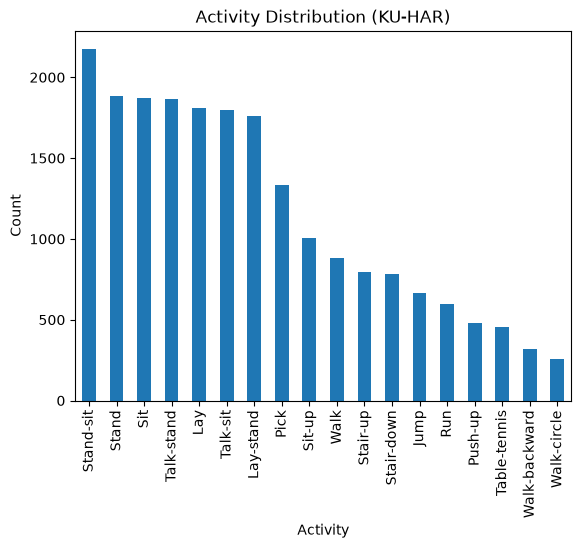

In [15]:
import matplotlib.pyplot as plt

activity_counts.plot(kind="bar")

plt.title("Activity Distribution (KU-HAR)")
plt.xlabel("Activity")
plt.ylabel("Count")
plt.xticks(rotation=90)

plt.show()

### 4.3 Interpretation der Aktivitätsverteilung

Die Verteilung der Aktivitäten zeigt, dass einige Bewegungsarten häufiger im Datensatz vertreten sind als andere. Dies kann Auswirkungen auf die spätere Analyse und das Clustering haben, da häufige Aktivitäten stärker gewichtet werden als seltene.

## 4.4 Statistische Übersicht der Aktivitätsverteilung

Um die quantitative Verteilung nicht nur visuell, sondern auch mathematisch präzise zu erfassen, wird in diesem Schritt eine zusammenfassende Statistik-Tabelle erstellt. Diese zeigt sowohl die absoluten Fallzahlen als auch die relativen prozentualen Anteile jeder Aktivitätsklasse am Gesamtdatensatz.

*   **`value_counts(normalize=True) * 100`**: Durch das Argument `normalize=True` berechnet Pandas anstelle der absoluten Zahlen die relativen Anteile (als Dezimalbruch zwischen 0 und 1). Die Multiplikation mit `100` wandelt diese Werte in intuitive Prozentangaben um.
*   **`pd.DataFrame({...})`**: Kombiniert die beiden separaten Serien (`activity_counts` und `activity_percent`) zu einer neuen, übersichtlichen Tabelle (DataFrame) mit den Spalten `"count"` und `"percentage"`.

#### Mathematische Kern-Erkenntnisse:
*   Die drei am stärksten vertretenen Aktivitäten (`Stand-sit`, `Stand`, `Sit`) machen zusammen knapp **28,6 %** des gesamten Datensatzes aus.
*   Die Klasse `Stand-sit` stellt mit **10,50 %** den größten Einzelanteil dar.
*   Die seltenste Klasse `Walk-circle` macht lediglich **1,25 %** der Daten aus.
*   Der Unterschied zwischen der stärksten und der schwächsten Klasse beträgt rechnerisch das **8,4-fache**. Diese quantitative Übersicht untermauert die Notwendigkeit, bei der späteren Modellierung auf die Robustheit der Algorithmen gegenüber dieser ungleichen Klassenverteilung zu achten.

In [16]:
activity_counts = df_kuhar["activity_name"].value_counts()

activity_percent = df_kuhar["activity_name"].value_counts(normalize=True) * 100

df_activity_stats = pd.DataFrame({
    "count": activity_counts,
    "percentage": activity_percent
})

df_activity_stats

,count,percentage
activity_name,,
Stand-sit,2178,10.496891
Stand,1885,9.084775
Sit,1874,9.031761
Talk-stand,1866,8.993204
Lay,1813,8.737770
Talk-sit,1797,8.660658
Lay-stand,1762,8.491976
Pick,1333,6.424406
Sit-up,1005,4.843607


## 4.5 Gruppierung der Aktivitäten (Makro-Ebene)

Um die Komplexität der 18 einzelnen Aktivitätsklassen zu reduzieren und Muster auf einer höheren Verhaltensebene zu untersuchen, werden die Aktivitäten in zwei übergeordnete Kategorien aggregiert: **aktiv** (`active`) und **inaktiv** (`inactive`).

*   **`activity_group_map`**: Ein Dictionary, das jede der 18 spezifischen Aktivitäten logisch einer der beiden Makro-Klassen zuordnet. Statische Haltungen wie Sitzen, Stehen oder Liegen (auch in Kombination mit Reden) werden als `inactive` definiert. Dynamische Bewegungen (Gehen, Laufen, Sportübungen) werden als `active` deklariert.
*   **`.map(activity_group_map)`**: Wendet diese Logik auf die Spalte `activity_name` an und erzeugt die neue Analysegruppe `activity_group`.
*   **`value_counts()`**: Berechnet die Verteilung auf dieser neuen Makro-Ebene.

In [17]:
activity_group_map = {
    "Stand": "inactive",
    "Sit": "inactive",
    "Lay": "inactive",

    "Talk-sit": "inactive",
    "Talk-stand": "inactive",

    "Walk": "active",
    "Walk-backward": "active",
    "Walk-circle": "active",
    "Run": "active",
    "Stair-up": "active",
    "Stair-down": "active",

    "Jump": "active",
    "Push-up": "active",
    "Sit-up": "active",

    "Pick": "active",
    "Stand-sit": "active",
    "Lay-stand": "active",

    "Table-tennis": "active"
}

df_kuhar["activity_group"] = df_kuhar["activity_name"].map(activity_group_map)

In [18]:
df_kuhar["activity_group"].value_counts()

activity_group
active      11514
inactive     9235
Name: count, dtype: int64

### 4.6 Interpretation der Gruppierung

Die Gruppierung zeigt das Verhältnis von aktiven zu inaktiven Aktivitäten. Dies ermöglicht eine vereinfachte Analyse des Bewegungsverhaltens und bildet eine Grundlage für spätere Cluster- und Vergleichsanalysen.

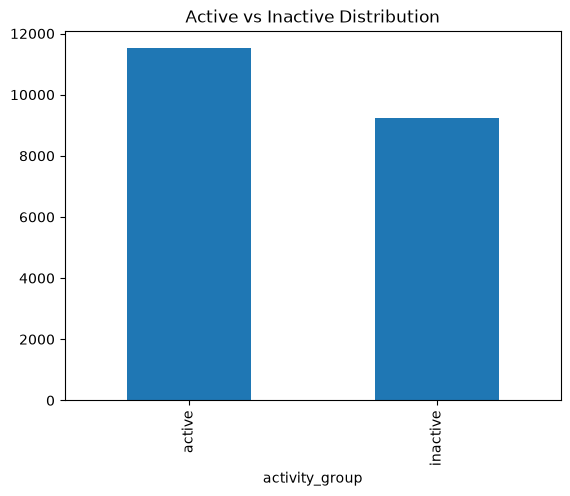

In [19]:
df_kuhar["activity_group"].value_counts().plot(kind="bar")
plt.title("Active vs Inactive Distribution")
plt.show()

## 5. HAR70+ Daten Überblick

Ziel dieses Abschnitts ist ein erster struktureller Überblick über den HAR70+ Datensatz, inklusive Datenform, Verteilung und grundlegender statistischer Eigenschaften.

In [20]:
df_har70.shape

(1832560, 8)

In [21]:
df_har70.head()

,timestamp,back_x,back_y,back_z,thigh_x,thigh_y,thigh_z,label
0,2021-03-24 14:42:03.839,-0.999023,-0.063477,0.140625,-0.980469,-0.112061,-0.048096,6
1,2021-03-24 14:42:03.859,-0.980225,-0.079346,0.140625,-0.961182,-0.121582,-0.051758,6
2,2021-03-24 14:42:03.880,-0.950195,-0.076416,0.140625,-0.949463,-0.080566,-0.067139,6
3,2021-03-24 14:42:03.900,-0.954834,-0.059082,0.140381,-0.957520,-0.046143,-0.050781,6
4,2021-03-24 14:42:03.920,-0.972412,-0.042969,0.142822,-0.977051,-0.023682,-0.026611,6


In [22]:
df_har70.describe()

,back_x,back_y,back_z,thigh_x,thigh_y,thigh_z,label
count,1.832560e+06,1.832560e+06,1.832560e+06,1.832560e+06,1.832560e+06,1.832560e+06,1.832560e+06
mean,-8.683814e-01,-3.178814e-02,2.244210e-02,-6.763959e-01,8.185066e-03,-3.858819e-01,3.940692e+00
std,2.756643e-01,1.556768e-01,4.279549e-01,5.596829e-01,2.707317e-01,5.087015e-01,2.912512e+00
min,-4.333252e+00,-2.031006e+00,-2.204834e+00,-7.942139e+00,-5.142578e+00,-7.593750e+00,1.000000e+00
25%,-9.909670e-01,-1.093750e-01,-2.692870e-01,-9.855960e-01,-1.132810e-01,-9.770510e-01,1.000000e+00
50%,-9.377440e-01,-1.855500e-02,-9.399400e-02,-9.357910e-01,-1.464800e-02,-1.906740e-01,3.000000e+00
75%,-8.344730e-01,5.761700e-02,3.078610e-01,-7.763700e-02,1.230470e-01,-3.174000e-03,7.000000e+00
max,3.630370e-01,1.576660e+00,1.179199e+00,3.395264e+00,5.725098e+00,3.953369e+00,8.000000e+00


In [23]:
df_har70.info()

<class 'pandas.DataFrame'>
RangeIndex: 1832560 entries, 0 to 1832559
Data columns (total 8 columns):
 #   Column     Dtype  
---  ------     -----  
 0   timestamp  str    
 1   back_x     float64
 2   back_y     float64
 3   back_z     float64
 4   thigh_x    float64
 5   thigh_y    float64
 6   thigh_z    float64
 7   label      int64  
dtypes: float64(6), int64(1), str(1)
memory usage: 111.9 MB


In [24]:
df_har70.isnull().sum().sum()

np.int64(0)

## 6. Vergleich KU-HAR vs. HAR70+

In diesem methodischen Schritt werden die beiden Datensätze bezüglich ihrer Dimensionen, der Feature-Anzahl und der zugrundeliegenden Datentypen direkt gegenübergestellt. Ziel ist es, die strukturelle Inkompatibilität der Rohformate quantitativ zu belegen.

*   **`df.dtypes.value_counts()`**: Diese Funktion gruppiert alle Spalten eines DataFrames nach ihrem Datentyp und zählt, wie oft jeder Typ vorkommt. Das gibt einen schnellen Überblick über die Zusammensetzung der Daten (z. B. rein numerisch vs. Textkomponenten).

### 6.1 Vergleich der Datenstruktur und Größe

In [25]:
print("KU-HAR shape:", df_kuhar.shape)
print("HAR70 shape:", df_har70.shape)

KU-HAR shape: (20749, 1805)
HAR70 shape: (1832560, 8)


### 6.2 Vergleich der Anzahl Features

In [26]:
print("KU-HAR columns:", len(df_kuhar.columns))
print("HAR70 columns:", len(df_har70.columns))

KU-HAR columns: 1805
HAR70 columns: 8


### 6.3 Datentypenvergleich

In [27]:
df_kuhar.dtypes.value_counts()

float64    1800
int64         3
str           2
Name: count, dtype: int64

In [28]:
df_har70.dtypes.value_counts()

float64    6
str        1
int64      1
Name: count, dtype: int64

### 6.4 Interpretation der Unterschiede (Synthese)

Der direkte Vergleich liefert folgendes Ergebnis:

1.  **KU-HAR (Stark vorverarbeitet / Labor):** 
    *   `1.800` Spalten vom Typ `float64` (kontinuierliche Features) und `3` vom Typ `int64` (Zielvariablen/IDs).
    *   **Charakteristik:** Ein klassischer "breiter" Datensatz (*wide format*). Die zeitliche Dynamik wurde bereits in Spalten transformiert.
2.  **HAR70+ (Rohdaten / Alltag):**
    *   Nur `6` Spalten vom Typ `float64` (die reinen Sensorachsen), `1` Zeitstempel (`str`) und `1` Zielvariable (`int64`).
    *   **Charakteristik:** Ein klassischer "langer" Datensatz (*long format*). Die zeitliche Dynamik steckt in der enormen Zeilenanzahl von über 1,8 Millionen Samples.

**Konsequenz für das Projekt:** Ein direkter zeilenweiser Vergleich oder ein einfaches Zusammenführen (Merge) ist unmöglich. Um HAR70+ für klassische Machine-Learning-Modelle (wie den Random Forest) nutzbar zu machen, müssen wir im nächsten Schritt **Feature Engineering** auf den Zeitreihen anwenden. Dabei werden die Rohdaten von HAR70+ ebenfalls in statistische Zeitfenster (z. B. Mittelwert und Energie über 5-Sekunden-Intervalle) zerlegt, um eine vergleichbare mathematische Struktur zu schaffen.

## 7. Feature-basierte Analyse

In diesem Schritt werden aus den Roh-Sensordaten statistische Kennzahlen berechnet, um Bewegungsmuster quantitativ zu beschreiben. Diese Features bilden die Grundlage für die spätere Segmentierung und Visualisierung.

### 7.1 Extraktion und Berechnung statistischer Features

Zunächst werden die 1.800 Spalten in die 6 zugrundeliegenden physikalischen Sensorkanäle (jeweils 300 Messpunkte pro Zeitfenster) zerlegt:
*   **Beschleunigung (Accelerometer):** `acc_x`, `acc_y`, `acc_z`
*   **Rotationsgeschwindigkeit (Gyroscope):** `gyro_x`, `gyro_y`, `gyro_z`

Über eine automatisierte Schleife werden für jeden dieser 6 Kanäle **4 statistische Kennzahlen** zeilenweise (`axis=1`) berechnet:

1.  **Mittelwert (`mean`)**: Spiegelt die statische Grundposition oder Orientierung des Sensors im Raum wider.
2.  **Varianz (`var`)**: Misst die Streuung der Signalwerte um den Mittelwert. Ein hoher Wert zeigt eine unruhige Bewegung an.
3.  **Standardabweichung (`std`)**: Die Quadratwurzel der Varianz. Sie beschreibt die durchschnittliche Abweichung vom Mittelwert in der Originaleinheit des Sensors.
4.  **Signalenergie (`energy`)**: Mathematisch berechnet als der Mittelwert der quadrierten Signalwerte (`(channel ** 2).mean(axis=1)`). Sie gibt Aufschluss über die kinetische Intensität und Wucht einer Bewegung (wichtig zur Unterscheidung von z. B. Gehen und Laufen).

**Ergebnis:** Durch diese Aggregation schrumpft die Anzahl der Sensor-Features von ursprünglich 1.800 auf exakt **24 statistische Merkmale** (6 Kanäle × 4 Kennzahlen). Zusammen mit den 3 Metadaten-Spalten (`activity`, `activity_name`, `activity_group`) besitzt der neue DataFrame `df_features` eine kompakte Dimension von `(20749, 27)`.

In [29]:
# Sensorkanäle definieren
acc_x = df_kuhar.iloc[:, 0:300]
acc_y = df_kuhar.iloc[:, 300:600]
acc_z = df_kuhar.iloc[:, 600:900]
gyro_x = df_kuhar.iloc[:, 900:1200]
gyro_y = df_kuhar.iloc[:, 1200:1500]
gyro_z = df_kuhar.iloc[:, 1500:1800]

df_features = df_kuhar[["activity", "activity_name", "activity_group"]].copy()

# Features pro Kanal berechnen
for name, channel in [("acc_x", acc_x), ("acc_y", acc_y), ("acc_z", acc_z),
                       ("gyro_x", gyro_x), ("gyro_y", gyro_y), ("gyro_z", gyro_z)]:
    df_features[f"mean_{name}"] = channel.mean(axis=1)
    df_features[f"var_{name}"] = channel.var(axis=1)
    df_features[f"std_{name}"] = channel.std(axis=1)
    df_features[f"energy_{name}"] = (channel ** 2).mean(axis=1)

print(df_features.shape)
df_features.head()

(20749, 27)


,activity,activity_name,activity_group,mean_acc_x,var_acc_x,std_acc_x,energy_acc_x,mean_acc_y,var_acc_y,std_acc_y,energy_acc_y,mean_acc_z,var_acc_z,std_acc_z,energy_acc_z,mean_gyro_x,var_gyro_x,std_gyro_x,energy_gyro_x,mean_gyro_y,var_gyro_y,std_gyro_y,energy_gyro_y,mean_gyro_z,var_gyro_z,std_gyro_z,energy_gyro_z
0,0,Stand,inactive,0.017644,0.001357,0.036833,0.001663,-0.004335,0.001247,0.035312,0.001262,0.024522,0.002459,0.049584,0.003052,-0.017521,0.000034,0.005821,0.000341,-0.000282,0.000137,0.011709,0.000137,-0.004295,0.000024,0.004935,0.000043
1,0,Stand,inactive,0.016109,0.001329,0.036454,0.001584,-0.006029,0.001522,0.039010,0.001553,0.028968,0.002584,0.050833,0.003415,-0.019206,0.000088,0.009359,0.000456,0.000625,0.000161,0.012671,0.000160,-0.005184,0.000038,0.006130,0.000064
2,0,Stand,inactive,0.021964,0.001493,0.038644,0.001971,-0.003591,0.000901,0.030022,0.000911,0.016261,0.001812,0.042563,0.002070,-0.019644,0.000084,0.009172,0.000470,-0.001668,0.000177,0.013306,0.000179,-0.005303,0.000029,0.005390,0.000057
3,0,Stand,inactive,0.018489,0.000767,0.027690,0.001106,-0.003646,0.000758,0.027536,0.000769,0.024755,0.000968,0.031117,0.001578,-0.021306,0.000173,0.013170,0.000627,0.001171,0.000048,0.006921,0.000049,-0.006366,0.000018,0.004232,0.000058
4,0,Stand,inactive,0.017501,0.000855,0.029240,0.001158,0.003276,0.000991,0.031483,0.000999,0.031877,0.001292,0.035950,0.002304,-0.002959,0.000158,0.012579,0.000166,-0.005173,0.000080,0.008956,0.000107,0.000369,0.000034,0.005856,0.000034


### Berechnung statistischer Features pro Sensorkanal

Für jeden der 6 Sensorkanäle (Accelerometer X/Y/Z und Gyroskop X/Y/Z) werden vier statistische Kennzahlen berechnet. Das ergibt insgesamt 24 Features pro Sample, die die Bewegungsintensität kanalspezifisch beschreiben.

## 7.2 Vorbereitung der Feature-Matrix und Standardisierung

Bevor ein distanzbasierter Machine-Learning-Algorithmus wie K-Means angewendet werden kann, müssen die Daten isoliert und mathematisch vorbereitet werden.

*   **Isolierung der Features (`feature_cols`)**: Über eine List Comprehension werden alle rein numerischen Sensor-Features gefiltert. Die Spalten für Metadaten (`activity`, `activity_name`, `activity_group`) sowie die spätere Cluster-Zuweisung werden explizit ausgeschlossen, damit das Modell nicht auf vordefinierte Labels zugreifen kann. Es entsteht die Feature-Matrix `X`.
*   **`StandardScaler()`**: Initialisiert das Werkzeug zur Standardisierung (Z-Transformation) der Daten.
*   **`scaler.fit_transform(X)`**: Berechnet für jedes Feature den Mittelwert ($\mu$) und die Standardabweichung ($\sigma$) und transformiert die Werte anschließend.

In [30]:
feature_cols = [col for col in df_features.columns if col not in ["activity", "activity_name", "activity_group", "cluster"]]

X = df_features[feature_cols]
X.head()

,mean_acc_x,var_acc_x,std_acc_x,energy_acc_x,mean_acc_y,var_acc_y,std_acc_y,energy_acc_y,mean_acc_z,var_acc_z,std_acc_z,energy_acc_z,mean_gyro_x,var_gyro_x,std_gyro_x,energy_gyro_x,mean_gyro_y,var_gyro_y,std_gyro_y,energy_gyro_y,mean_gyro_z,var_gyro_z,std_gyro_z,energy_gyro_z
0,0.017644,0.001357,0.036833,0.001663,-0.004335,0.001247,0.035312,0.001262,0.024522,0.002459,0.049584,0.003052,-0.017521,0.000034,0.005821,0.000341,-0.000282,0.000137,0.011709,0.000137,-0.004295,0.000024,0.004935,0.000043
1,0.016109,0.001329,0.036454,0.001584,-0.006029,0.001522,0.039010,0.001553,0.028968,0.002584,0.050833,0.003415,-0.019206,0.000088,0.009359,0.000456,0.000625,0.000161,0.012671,0.000160,-0.005184,0.000038,0.006130,0.000064
2,0.021964,0.001493,0.038644,0.001971,-0.003591,0.000901,0.030022,0.000911,0.016261,0.001812,0.042563,0.002070,-0.019644,0.000084,0.009172,0.000470,-0.001668,0.000177,0.013306,0.000179,-0.005303,0.000029,0.005390,0.000057
3,0.018489,0.000767,0.027690,0.001106,-0.003646,0.000758,0.027536,0.000769,0.024755,0.000968,0.031117,0.001578,-0.021306,0.000173,0.013170,0.000627,0.001171,0.000048,0.006921,0.000049,-0.006366,0.000018,0.004232,0.000058
4,0.017501,0.000855,0.029240,0.001158,0.003276,0.000991,0.031483,0.000999,0.031877,0.001292,0.035950,0.002304,-0.002959,0.000158,0.012579,0.000166,-0.005173,0.000080,0.008956,0.000107,0.000369,0.000034,0.005856,0.000034


In [31]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Da die Features unterschiedliche Skalen haben, werden sie standardisiert, um eine faire Grundlage für das Clustering zu schaffen.

## 8. Segmentierung (Clustering)

In diesem Schritt werden ähnliche Bewegungsmuster mithilfe eines unüberwachten Lernverfahrens (K-Means) gruppiert. Ziel ist es, typische Aktivitätsprofile basierend auf den berechneten Features zu identifizieren.

### 8.1 Durchführung des Clusterings

In [32]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df_features["cluster"] = kmeans.fit_predict(X_scaled)

df_features[["mean_acc_x", "energy_acc_x", "cluster"]].head()

,mean_acc_x,energy_acc_x,cluster
0,0.017644,0.001663,0
1,0.016109,0.001584,0
2,0.021964,0.001971,0
3,0.018489,0.001106,0
4,0.017501,0.001158,0


Das K-Means-Verfahren gruppiert die Datenpunkte basierend auf Ähnlichkeiten in den berechneten Features. Die Anzahl der Cluster wurde hier auf drei gesetzt, um grundlegende Bewegungsprofile zu identifizieren.

## 8.2 Verteilung der Cluster

Es wird die Anzahl der Datenpunkte pro Cluster analysiert, um zu sehen, wie der Algorithmus die Bewegungsmuster aufgeteilt hat.

*   **`df_features["cluster"].value_counts()`**: Zählt, wie viele Samples in Cluster 0, 1 und 2 gelandet sind.

#### Extrem wichtiges Ergebnis:
*   **Cluster 0**: 20.673 Samples (Die absolute Masse der Daten)
*   **Cluster 1**: 48 Samples (Sehr kleine Gruppe)
*   **Cluster 2**: 28 Samples (Sehr kleine Gruppe)

**Interpretation:** Der K-Means-Algorithmus hat ein extremes Ungleichgewicht erzeugt. Er packt fast alle Datenpunkte in Cluster 0. Die Cluster 1 und 2 verhalten sich wie mathematische **Ausreißer (Outlier)**. Das liegt daran, dass K-Means sehr empfindlich auf Aktivitäten mit extrem hoher Energie (wie z. B. Laufen oder Springen) reagiert und diese sofort isoliert, während alle moderaten Bewegungen (Sitzen, Stehen, normales Gehen) in einer einzigen großen Gruppe landen.

In [33]:
df_features["cluster"].value_counts()

cluster
0    20673
1       48
2       28
Name: count, dtype: int64

Die Verteilung zeigt, wie die Daten auf die einzelnen Cluster aufgeteilt sind und gibt Hinweise darauf, ob bestimmte Bewegungsmuster dominieren.

## 8.3 Vergleich von Clustern und Aktivitätslabels & PCA-Visualisierung

In diesem Schritt wird die mathematische Ursache für das ungleiche Clustering aufgedeckt und die Daten für ein Diagramm vorbereitet.

*   **`pd.crosstab(...)`**: Erstellt eine Kreuztabelle zwischen den echten Aktivitätsnamen und den vom Modell vergebenen Clustern.
*   **Erkenntnis der Kreuztabelle**: Es wird sofort sichtbar, dass fast alle Aktivitäten komplett in **Cluster 0** liegen. Die einzige Ausnahme ist **"Run" (Laufen)**: Ein Teil davon wurde abgespalten und bildet exklusiv die Ausreißer-Cluster 1 und 2. Das bestätigt die Vermutung eines energetischen Ausreißers.
*   **`PCA(n_components=2)`**: Da man 24 Features nicht in einem normalen Diagramm zeichnen kann, reduziert die Hauptkomponentenanalyse (PCA) die Daten auf die 2 wichtigsten Richtungen (Hauptkomponenten PC1 und PC2).

In [34]:
pd.crosstab(df_features["activity_name"], df_features["cluster"]).head(10)

cluster,0,1,2
activity_name,,,
Jump,666,0,0
Lay,1813,0,0
Lay-stand,1762,0,0
Pick,1333,0,0
Push-up,480,0,0
Run,519,48,28
Sit,1874,0,0
Sit-up,1005,0,0
Stair-down,781,0,0


Durch den Vergleich der Cluster mit den tatsächlichen Aktivitätslabels kann beurteilt werden, wie gut das Clustering die realen Bewegungsmuster widerspiegelt.

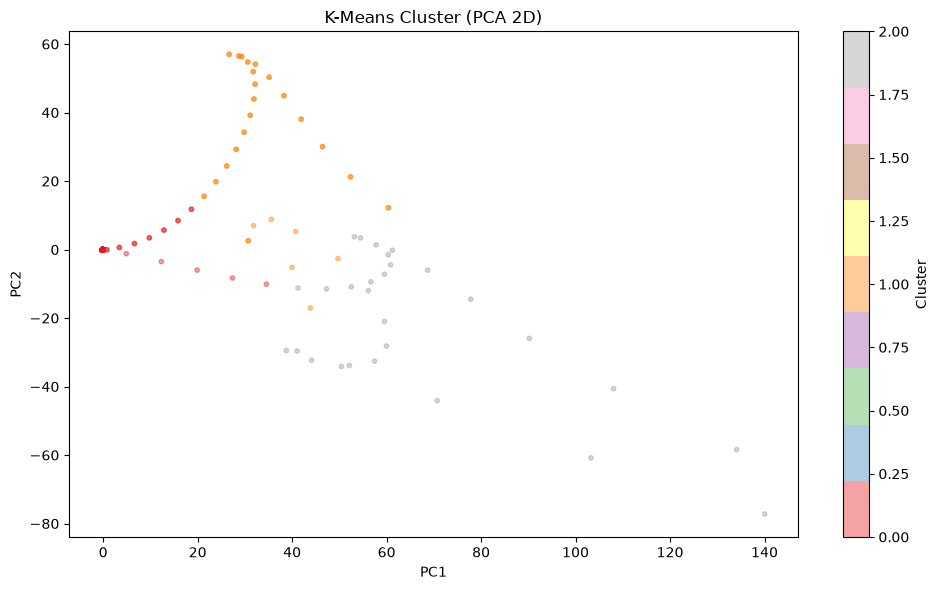

In [35]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], 
                      c=df_features["cluster"], cmap="Set1", alpha=0.4, s=10)
plt.colorbar(scatter, label="Cluster")
plt.title("K-Means Cluster (PCA 2D)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()

## 8.4 Visuelle Analyse des K-Means Clusterings via PCA (2D)

Das Diagramm zeigt die Verteilung der Datenpunkte nach der Reduktion auf die ersten beiden Hauptkomponenten (PC1 und PC2). Die Einfärbung repräsentiert die drei K-Means-Cluster.

#### Visuelle Erkenntnisse:
*   **Cluster 0 (Rot, unten links bei 0):** Hier ballt sich die absolute Mehrheit aller Datenpunkte (über 20.000 Samples). Alle alltäglichen und statischen Aktivitäten liegen hier extrem dicht beieinander.
*   **Cluster 1 (Orange, nach oben gestreckt) & Cluster 2 (Grau, nach rechts gestreckt):** Bilden zwei lange, weit verzweigte Arme, die sich massiv vom Hauptzentrum entfernen.
*   **Interpretation:** Die Grafik untermauert das mathematische Ergebnis visuell: Laufen (Run) bricht aufgrund seiner physikalischen Intensität komplett aus dem normalen Bewegungsmuster aus. K-Means nutzt zwei Cluster, um die extremen Ausschläge auf den Achsen PC1 und PC2 abzufangen, während der "Rest" der menschlichen Bewegung als einheitlicher Block (Cluster 0) wahrgenommen wird.

## 9. Klassifikation mit Random Forest

In diesem Abschnitt wird ein überwachtes Lernverfahren (Random Forest) eingesetzt, 
um Aktivitäten anhand der berechneten Features vorherzusagen. 
Ziel ist es, die Klassifikationsgenauigkeit zu messen und zu bewerten, 
wie gut die Features die einzelnen Aktivitäten unterscheiden können.

## 9.1 Auswertung des Random Forest Modells für KU-HAR

Der `classification_report` zeigt die Leistung des Modells auf den versteckten Testdaten (20 % des Datensatzes).

In [36]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

X = df_features[feature_cols]
y = df_features["activity_name"]

# NaN-Zeilen entfernen
mask = y.notna()
X = X[mask]
y = y[mask]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

print(classification_report(y_test, y_pred))

               precision    recall  f1-score   support

         Jump       0.96      0.94      0.95       127
          Lay       0.96      0.91      0.93       355
    Lay-stand       0.98      0.94      0.96       344
         Pick       0.88      0.93      0.91       267
      Push-up       0.95      0.92      0.94        89
          Run       0.94      0.95      0.94       141
          Sit       0.95      0.92      0.93       399
       Sit-up       0.93      0.82      0.87       218
   Stair-down       0.91      0.92      0.91       175
     Stair-up       0.89      0.92      0.91       157
        Stand       0.86      0.93      0.89       327
    Stand-sit       0.93      0.98      0.95       448
 Table-tennis       0.93      0.92      0.92        97
     Talk-sit       0.92      0.94      0.93       367
   Talk-stand       0.91      0.97      0.94       348
         Walk       0.85      0.88      0.87       163
Walk-backward       0.71      0.52      0.60        67
  Walk-ci

## 9.2 Visualisierung der Konfusionsmatrix (Confusion Matrix)

Die Konfusionsmatrix zeigt detailliert, welche Aktivitäten das Modell korrekt erkannt hat und wo es zu Verwechslungen kam.


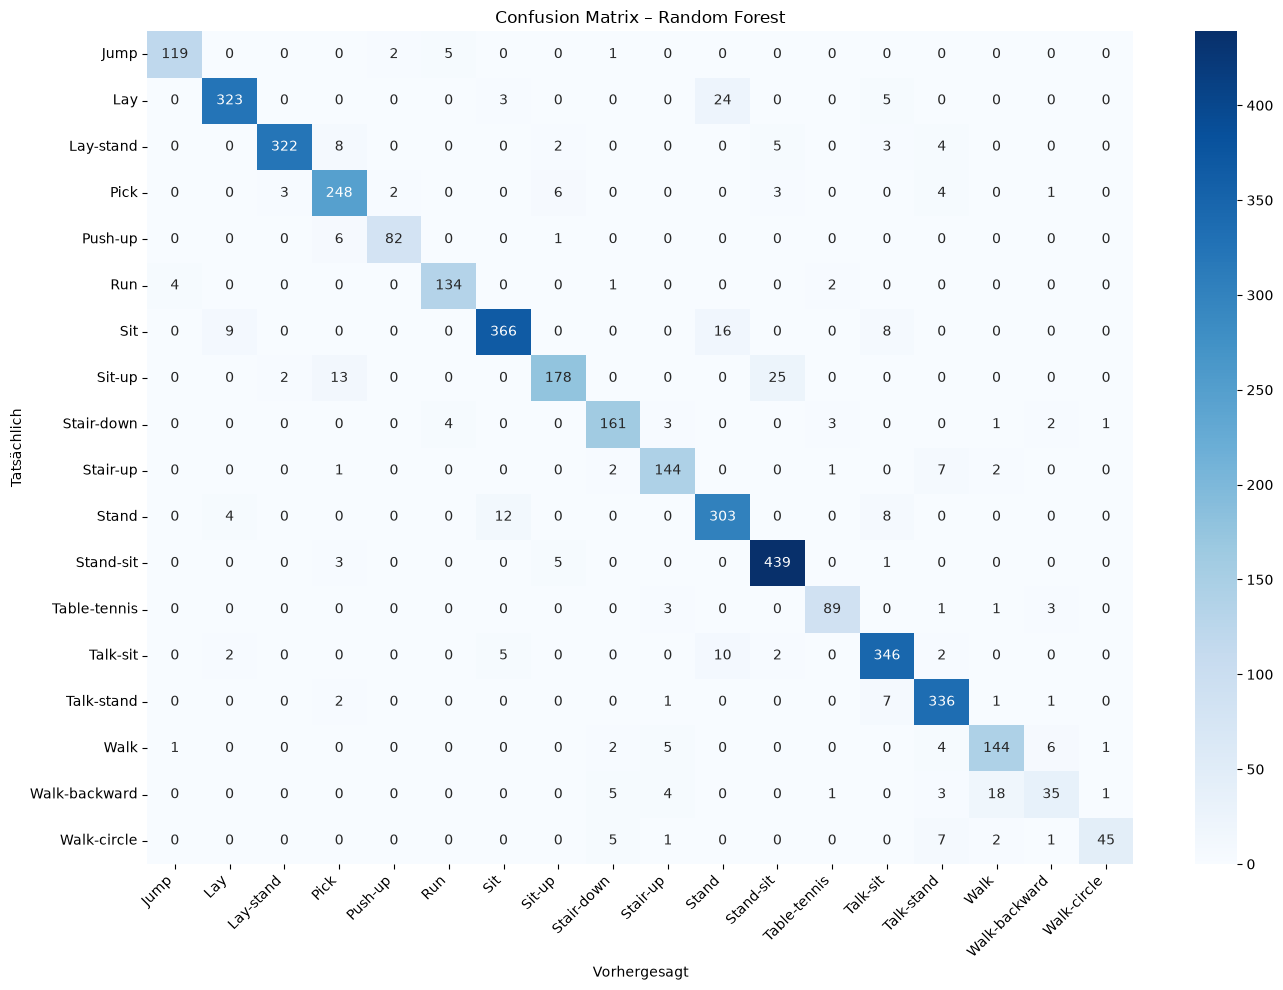

In [37]:
cm = confusion_matrix(y_test, y_pred, labels=rf.classes_)

plt.figure(figsize=(14, 10))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=rf.classes_, yticklabels=rf.classes_, cmap="Blues")
plt.title("Confusion Matrix – Random Forest")
plt.xlabel("Vorhergesagt")
plt.ylabel("Tatsächlich")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 9.3 Random Forest für HAR70

In [38]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split

# ==============================================================================
# 1. FEATURE ENGINEERING (Rohdaten in 3-Sekunden-Fenster schneiden)
# ==============================================================================
# HAR70+ hat 50 Hz Abtastrate. 3 Sekunden entsprechen genau 150 Zeitschritten.
window_size = 150
df_har70["window_id"] = np.arange(len(df_har70)) // window_size

# Aggregation der mathematischen Features pro Fenster
features_har70 = (
    df_har70.groupby("window_id")
    .agg(
        {
            "back_x": ["mean", "var", "std"],
            "back_y": ["mean", "var", "std"],
            "back_z": ["mean", "var", "std"],
            "thigh_x": ["mean", "var", "std"],
            "thigh_y": ["mean", "var", "std"],
            "thigh_z": ["mean", "var", "std"],
            "label": lambda x: x.mode()[0] if not x.mode().empty else x.iloc[0],
        }
    )
    .dropna()
)

# Spaltennamen glätten & Zielvariable umbenennen
features_har70.columns = ["_".join(col) for col in features_har70.columns]
features_har70 = features_har70.rename(columns={"label_<lambda>": "activity"})

# ==============================================================================
# 2. DATA SPLIT (Features und Labels trennen)
# ==============================================================================
X_har70 = features_har70.drop(columns=["activity"])
y_har70 = features_har70["activity"]

# Train-Test-Split (80% Training, 20% Validierung)
X_train, X_test, y_train, y_test = train_test_split(
    X_har70, y_har70, test_size=0.2, random_state=42, stratify=y_har70
)

# ==============================================================================
# 3. MODEL TRAINING & EVALUATION (Random Forest)
# ==============================================================================
# Random Forest definieren und trainieren
rf_har70 = RandomForestClassifier(
    n_estimators=100, max_depth=15, random_state=42, n_jobs=-1
)
rf_har70.fit(X_train, y_train)

# Vorhersage auf den ungesehenen Testdaten
y_pred = rf_har70.predict(X_test)

# Ergebnisse ausgeben
print(
    f"✅ HAR70+ Modell erfolgreich trainiert! Test-Accuracy: {accuracy_score(y_test, y_pred):.4f}"
)
print("\nDetaillierter Klassifikationsbericht pro Aktivität:")
print(classification_report(y_test, y_pred))

✅ HAR70+ Modell erfolgreich trainiert! Test-Accuracy: 0.9579

Detaillierter Klassifikationsbericht pro Aktivität:
              precision    recall  f1-score   support

           1       0.96      0.98      0.97      1173
           3       0.54      0.25      0.34        52
           4       0.60      0.60      0.60         5
           5       1.00      0.17      0.29         6
           6       0.92      0.93      0.93       460
           7       0.99      1.00      1.00       509
           8       1.00      1.00      1.00       239

    accuracy                           0.96      2444
   macro avg       0.86      0.70      0.73      2444
weighted avg       0.95      0.96      0.95      2444



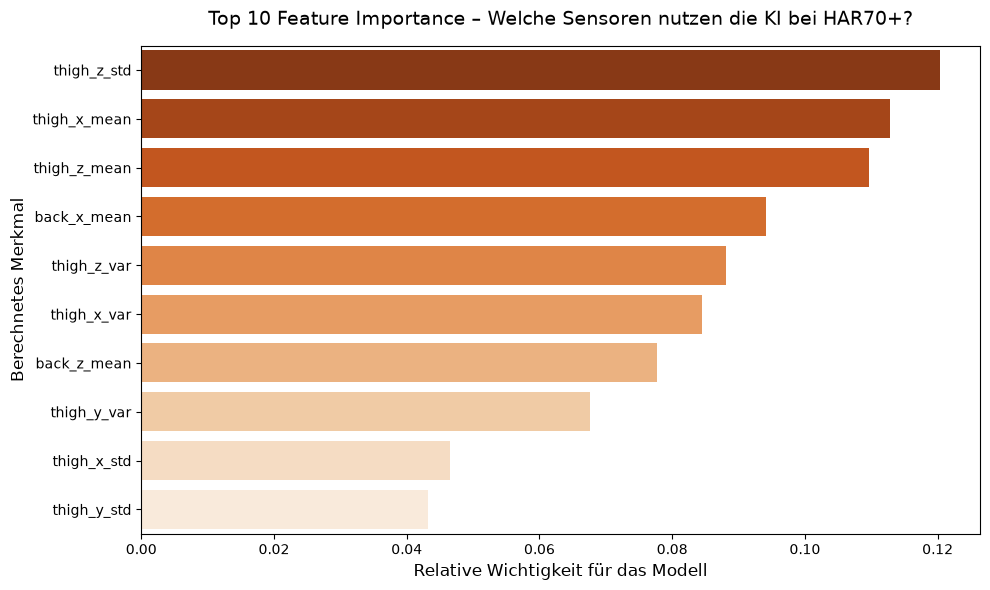

In [39]:
# 1. Feature-Wichtigkeiten aus dem Modell auslesen
importances = rf_har70.feature_importances_
feature_names = X_har70.columns

# 2. In ein übersichtliches DataFrame verpacken und sortieren
df_importance = pd.DataFrame(
    {"Feature": feature_names, "Wichtigkeit": importances}
).sort_values(by="Wichtigkeit", ascending=False)

# 3. Das Diagramm zeichnen (Die Top 10 wichtigsten Merkmale)
plt.figure(figsize=(10, 6))
sns.barplot(
    x="Wichtigkeit",
    y="Feature",
    data=df_importance.head(10),
    hue="Feature",       # Behebt die Warnung
    palette="Oranges_r",
    legend=False         # Verhindert eine störende Legende
)

plt.title(
    "Top 10 Feature Importance – Welche Sensoren nutzen die KI bei HAR70+?",
    fontsize=14,
    pad=15,
)
plt.xlabel("Relative Wichtigkeit für das Modell", fontsize=12)
plt.ylabel("Berechnetes Merkmal", fontsize=12)
plt.tight_layout()
plt.show()


## 10. Vergleichsanalyse KU-HAR vs HAR70+

In diesem Abschnitt werden die beiden Datensätze hinsichtlich ihrer Bewegungsmuster verglichen. KU-HAR repräsentiert jüngere Probanden mit hochdimensionalen vorverarbeiteten Features, während HAR70+ ältere Probanden mit einfacheren Rohsensordaten enthält.

In [40]:
# Nur die sechs Sensorkanäle vergleichen; label und window_id sind keine Messwerte
sensor_cols = ["back_x", "back_y", "back_z", "thigh_x", "thigh_y", "thigh_z"]
har70_numeric = df_har70[sensor_cols]

df_har70_features = pd.DataFrame()
df_har70_features["mean"] = har70_numeric.mean(axis=1)
df_har70_features["var"] = har70_numeric.var(axis=1)
df_har70_features["std"] = har70_numeric.std(axis=1)
df_har70_features["energy"] = (har70_numeric ** 2).mean(axis=1)
df_har70_features["dataset"] = "HAR70+"

df_kuhar_compare = pd.DataFrame()
df_kuhar_compare["mean"] = df_features["mean_acc_x"].values
df_kuhar_compare["var"] = df_features["var_acc_x"].values
df_kuhar_compare["std"] = df_features["std_acc_x"].values
df_kuhar_compare["energy"] = df_features["energy_acc_x"].values
df_kuhar_compare["dataset"] = "KU-HAR"

df_compare = pd.concat([df_kuhar_compare, df_har70_features], ignore_index=True)

df_compare.groupby("dataset")[["mean", "var", "std", "energy"]].mean()

,mean,var,std,energy
dataset,,,,
HAR70+,-0.321970,0.303218,0.536209,3.817954e-01
KU-HAR,-54.780617,45340.484020,12.828015,1.849783e+07


### 10.1 Vergleich der statistischen Features zwischen den Datensätzen

Hinweis: KU-HAR misst in m/s² (hier nur `acc_x` als Referenzkanal), HAR70+ in g über alle sechs Kanäle. Die Verteilungen sind daher nur in ihrer Form, nicht in absoluten Werten vergleichbar.


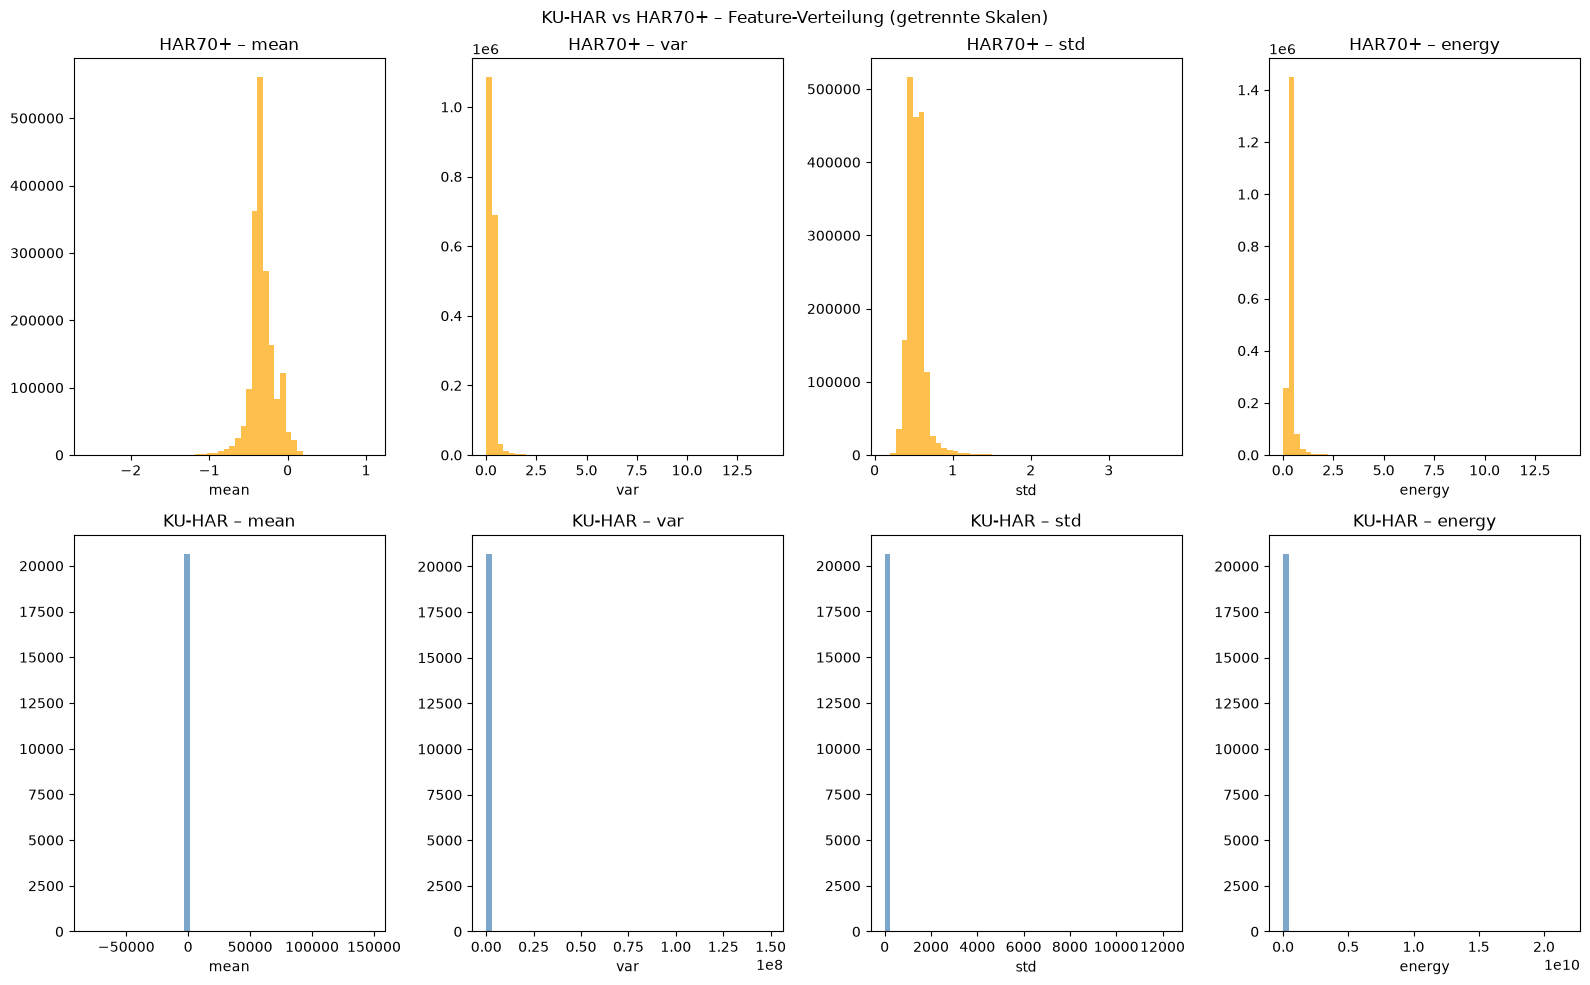

In [41]:
fig, axes = plt.subplots(2, 4, figsize=(16, 10))

for i, feature in enumerate(["mean", "var", "std", "energy"]):
    for j, (dataset, group) in enumerate(df_compare.groupby("dataset")):
        axes[j, i].hist(group[feature], bins=50, alpha=0.7, 
                        color="steelblue" if dataset == "KU-HAR" else "orange")
        axes[j, i].set_title(f"{dataset} – {feature}")
        axes[j, i].set_xlabel(feature)

plt.suptitle("KU-HAR vs HAR70+ – Feature-Verteilung (getrennte Skalen)")
plt.tight_layout()
plt.show()

### 10.2 Cluster-Profile: Welche Aktivitäten dominieren welchen Cluster?

In [42]:
cluster_profile = df_features.groupby(["cluster", "activity_name"])[["mean_acc_x", "energy_acc_x"]].mean().round(4)
print(cluster_profile)

                       mean_acc_x  energy_acc_x
cluster activity_name                          
0       Jump               0.8839  1.814618e+02
        Lay               -0.0070  3.600000e-03
        Lay-stand          0.0085  8.862000e-01
        Pick              -0.1523  2.376800e+00
        Push-up           -0.1956  4.260800e+00
        Run               -4.1604  8.159737e+06
        Sit                0.0065  1.000000e-03
        Sit-up            -0.0516  2.739200e+00
        Stair-down         0.1722  3.255690e+01
        Stair-up           0.1060  8.930300e+00
        Stand              0.0044  1.500000e-03
        Stand-sit          0.0210  1.729200e+00
        Table-tennis      -0.1085  2.129020e+01
        Talk-sit           0.0035  1.860000e-02
        Talk-stand         0.0098  1.143200e+00
        Walk               0.0616  1.005990e+01
        Walk-backward      0.0399  9.013200e+00
        Walk-circle        0.0835  6.575700e+00
1       Run           -47736.8813  3.146

## 11. Visualisierung der Cluster-Aktivitätsverteilung (Heatmap)

In diesem Schritt wird die Verteilung der realen Aktivitäten auf die drei berechneten K-Means-Cluster grafisch als Heatmap dargestellt.

*   **`sns.heatmap(cluster_counts, ...)`**: Erstellt die farbige Übersicht der Kreuztabelle. Dunkelblaue Flächen signalisieren eine hohe Anzahl an Datenpunkten.
*   **Visueller Beweis**: Die Grafik verdeutlicht das Problem des distanzbasierten Clusterings bei diesem Datensatz. Alle statischen und moderaten Aktivitäten sammeln sich als massiver, dunkelblauer Block komplett in **Cluster 0**. 
*   **Ausreißer-Sichtbarkeit**: Nur die Aktivität **"Run"** bricht aus und füllt die ansonsten komplett leeren Cluster 1 und 2 mit vereinzelten Punkten (48 und 28 Samples).

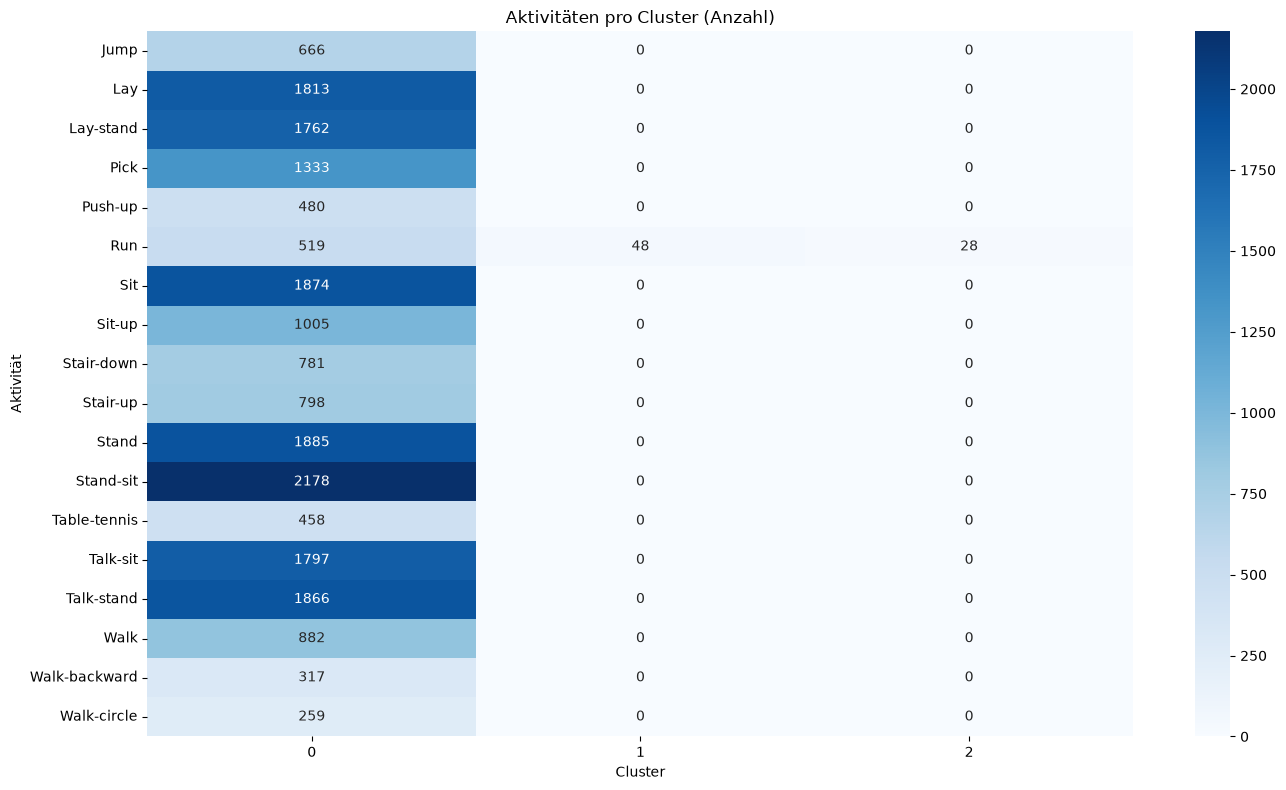

In [43]:
cluster_counts = pd.crosstab(df_features["activity_name"], df_features["cluster"])

plt.figure(figsize=(14, 8))
sns.heatmap(cluster_counts, annot=True, fmt="d", cmap="Blues")
plt.title("Aktivitäten pro Cluster (Anzahl)")
plt.xlabel("Cluster")
plt.ylabel("Aktivität")
plt.tight_layout()
plt.show()

## 12. Interpretation der Ergebnisse

### Zusammenfassung der wichtigsten Erkenntnisse

**KU-HAR Datensatz:**
Die Analyse zeigt, dass menschliche Bewegungsmuster anhand statistischer Features (Mittelwert, Varianz, Standardabweichung, Energie) gut unterscheidbar sind. Der Random Forest Klassifikator erreicht eine Accuracy von 92 % bei einem gewichteten F1-Score von 0,92. Begünstigt wird das durch die hohe Qualität und Vorverarbeitung des KU-HAR Datensatzes. Die verbleibenden Fehler betreffen vor allem ähnliche Gangarten: Walk-backward erreicht nur einen F1-Score von 0,60, Walk-circle 0,83.

**Clustering:**
Das K-Means Clustering mit 3 Clustern zeigt, dass Laufaktivitäten (Run) aufgrund ihrer extrem hohen Signalenergie als Ausreißer in eigene Cluster separiert werden. Alle anderen Aktivitäten gruppieren sich in einem gemeinsamen Cluster, was die unterschiedliche Intensität zwischen Laufen und anderen Bewegungsformen verdeutlicht.

**Vergleich KU-HAR vs HAR70+:**
Die beiden Datensätze unterscheiden sich deutlich in ihrer Struktur und Skalierung. KU-HAR enthält hochdimensionale vorverarbeitete Features mit hohen numerischen Werten, während HAR70+ einfachere Rohsensordaten mit kleineren Wertebereichen liefert. Dies spiegelt den Unterschied zwischen jüngeren (KU-HAR) und älteren Probanden (HAR70+) sowie zwischen Labor- und Alltagsmessungen wider.

**Aktiv vs. Inaktiv:**
Die Gruppierung der Aktivitäten in aktive und inaktive Zustände zeigt eine klare Dominanz aktiver Bewegungsmuster im KU-HAR Datensatz, was auf den kontrollierten Erhebungskontext hinweist.

### Datensatzstruktur KU-HAR

Jeder der 20.750 Samples enthält 3 Sekunden Sensordaten mit einer Abtastrate von 100 Hz, aufgeteilt in 6 Sensorkanäle:

- Spalten 1–300: Accelerometer X-Achse (m/s²)
- Spalten 301–600: Accelerometer Y-Achse (m/s²)
- Spalten 601–900: Accelerometer Z-Achse (m/s²)
- Spalten 901–1200: Gyroskop X-Achse (rad/s)
- Spalten 1201–1500: Gyroskop Y-Achse (rad/s)
- Spalten 1501–1800: Gyroskop Z-Achse (rad/s)

Die statistischen Features (Mittelwert, Varianz, Standardabweichung, Energie) wurden über alle 1800 Sensorwerte pro Sample berechnet, was eine kompakte Repräsentation der Bewegungsintensität ermöglicht.